# 05 — Paderborn: Scaled Benchmark, Bearing-Held-Out (25 bearings)

Notebook 04's headline number — 100% in-domain collapsing to 20.8% on real
damage — carried one uncomfortable caveat: **each class x domain cell was a
single physical bearing.** "Domain gap" and "bearing identity" were
confounded, and the in-domain 100% was partly an easy holdout (other 4-second
recordings of the *same* bearing, not a different bearing).

This notebook fixes both problems with the full Paderborn benchmark set
(`src/download_paderborn.py`, 25 bearings):

| Domain | Fault | Bearings | n |
|---|---|---|---|
| healthy | — | K001–K006 | 6 |
| artificial | OR | KA01(EDM) KA03(engraver) KA05(engraver) KA07(drill) | 4 |
| artificial | IR | KI01(EDM) KI03(engraver) KI05(engraver) KI07(drill) | 4 |
| real | OR | KA04 KA15 KA16 KA22 KA30 | 5 |
| real | IR | KI04 KI14 KI16 KI17 KI18 KI21 | 6 |

Two structural upgrades over notebook 04:

1. **In-domain ceiling = leave-one-*bearing*-out**, not leave-one-*recording*-out.
   The model is now scored on a bearing it has never seen at all — the honest
   comparison point for "does this generalize."
2. **The transfer number becomes a distribution.** Train once on all 14
   healthy+artificial bearings, then score each of the 11 real bearings
   *separately* — 20.8% either turns out to be typical, or it turns out to be
   the unlucky end of a spread. Either answer matters for the digital twin.

Same feature extraction as notebook 03 (envelope-band SNR + current-sideband
SNR, condition `N15_M07_F10`), same 12 columns, just run over 25 bearings
instead of 5.

In [1]:
import functools
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, hilbert, get_window
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_score

DATA_DIR = pathlib.Path("../data/raw/paderborn")
CONDITION = "N15_M07_F10"
FS_HIGH_HZ = 64_000

# (code, Condition, Domain) - Condition is the 3-class target, Domain is how
# the damage was produced (or "healthy").
BEARINGS = (
    [(f"K00{i}", "Healthy", "healthy") for i in range(1, 7)]
    + [(c, "OR", "artificial") for c in ("KA01", "KA03", "KA05", "KA07")]
    + [(c, "IR", "artificial") for c in ("KI01", "KI03", "KI05", "KI07")]
    + [(c, "OR", "real") for c in ("KA04", "KA15", "KA16", "KA22", "KA30")]
    + [(c, "IR", "real") for c in ("KI04", "KI14", "KI16", "KI17", "KI18", "KI21")]
)
print(f"{len(BEARINGS)} bearings x 20 runs -> "
      f"{sum(1 for _, _, d in BEARINGS if d != 'real') } train-domain, "
      f"{sum(1 for _, _, d in BEARINGS if d == 'real')} real bearings")

# Test bearing: deep-groove ball bearing 6203 (Lessmeier et al. 2016) - same as notebook 03
N_BALLS = 8
BALL_D_MM = 6.75
PITCH_D_MM = 29.05


def fault_freqs(fr):
    ratio = BALL_D_MM / PITCH_D_MM
    bpfo = N_BALLS / 2 * fr * (1 - ratio)
    bpfi = N_BALLS / 2 * fr * (1 + ratio)
    return bpfo, bpfi


def load_channels(mat_path):
    mat_path = pathlib.Path(mat_path)
    mat = loadmat(mat_path)
    struct = mat[mat_path.stem]
    channels = struct["Y"][0, 0][0]
    return {str(ch["Name"][0]): ch["Data"].squeeze() for ch in channels}


def pu_file(code, run):
    return DATA_DIR / code / f"{CONDITION}_{code}_{run}.mat"


N_KEEP = 245_760  # 15 windows x 16384 samples


@functools.lru_cache(maxsize=None)
def load_run(code, run):
    chans = load_channels(pu_file(code, run))
    fr = chans["speed"].mean() / 60.0
    return (chans["vibration_1"][:N_KEEP].astype(np.float32),
            chans["phase_current_1"][:N_KEEP].astype(np.float32),
            fr)


BAND_HZ = (1000, 20000)
SOS_ENV = butter(4, BAND_HZ, btype="bandpass", fs=FS_HIGH_HZ, output="sos")


def envelope(sig):
    env = np.abs(hilbert(sosfiltfilt(SOS_ENV, sig.astype(np.float64))))
    return env - env.mean()


WIN = 16_384
N_WIN = N_KEEP // WIN
HANN = get_window("hann", WIN)
WIN_FREQS = np.fft.rfftfreq(WIN, 1 / FS_HIGH_HZ)
FLOOR_MASK = (WIN_FREQS > 10) & (WIN_FREQS < 400)


def band_peak_db(spec, target, floor, halfwidth=4.0):
    band = (WIN_FREQS >= target - halfwidth) & (WIN_FREQS <= target + halfwidth)
    return 10 * np.log10(spec[:, band].max(axis=1) / floor)


def windowed_spectrum(sig):
    w = sig[: N_WIN * WIN].reshape(N_WIN, WIN)
    w = w - w.mean(axis=1, keepdims=True)
    spec = np.abs(np.fft.rfft(w * HANN, axis=1)) ** 2
    return w, spec


def run_features(code, run):
    vib, cur, fr = load_run(code, run)
    bpfo_r, bpfi_r = fault_freqs(fr)

    _, espec = windowed_spectrum(envelope(vib))
    efloor = np.median(espec[:, FLOOR_MASK], axis=1)
    v = vib[: N_WIN * WIN].reshape(N_WIN, WIN).astype(np.float64)
    vib_rms = np.sqrt(np.mean(v ** 2, axis=1))

    c, cspec = windowed_spectrum(cur.astype(np.float64))
    cfloor = np.median(cspec[:, FLOOR_MASK], axis=1)

    return pd.DataFrame({
        "Env_BPFO_dB":   band_peak_db(espec, bpfo_r, efloor),
        "Env_BPFOh2_dB": band_peak_db(espec, 2 * bpfo_r, efloor),
        "Env_BPFI_dB":   band_peak_db(espec, bpfi_r, efloor),
        "Env_BPFIh2_dB": band_peak_db(espec, 2 * bpfi_r, efloor),
        "Env_fr_dB":     band_peak_db(espec, fr, efloor),
        "Vib_RMS":         vib_rms,
        "Vib_CrestFactor": np.abs(v).max(axis=1) / vib_rms,
        "Cur_SBlow_dB":   band_peak_db(cspec, 100.0 - bpfo_r, cfloor),
        "Cur_SB_BPFO_dB": band_peak_db(cspec, 100.0 + bpfo_r, cfloor),
        "Cur_SB_BPFI_dB": band_peak_db(cspec, 100.0 + bpfi_r, cfloor),
        "Cur_Ecc_dB":     band_peak_db(cspec, 100.0 + fr, cfloor),
        "Cur_RMS": np.sqrt(np.mean(c ** 2, axis=1)),
    })

25 bearings x 20 runs -> 14 train-domain, 11 real bearings


## Feature extraction — 25 bearings x 20 runs x 15 windows = 7 500 rows

Same 12-column feature vocabulary as notebook 03 (nothing new is invented
here on purpose — this is a scale-up of an already-validated recipe, not a
new method). Takes a few minutes.

In [2]:
tables = []
for code, condition, domain in BEARINGS:
    for run in range(1, 21):
        feats = run_features(code, run)
        feats["Code"], feats["Condition"], feats["Domain"], feats["Run"] = code, condition, domain, run
        tables.append(feats)
dataset = pd.concat(tables, ignore_index=True)

OUT = pathlib.Path("../data/processed")
OUT.mkdir(parents=True, exist_ok=True)
csv_path = OUT / f"pu_{CONDITION}_spectral_features_scaled.csv"
dataset.to_csv(csv_path, index=False)
print(f"saved {len(dataset)} rows x {dataset.shape[1]} cols -> {csv_path}")
dataset.groupby(["Domain", "Condition"])["Code"].nunique()

saved 7500 rows x 16 cols -> ..\data\processed\pu_N15_M07_F10_spectral_features_scaled.csv


Domain      Condition
artificial  IR           4
            OR           4
healthy     Healthy      6
real        IR           6
            OR           5
Name: Code, dtype: int64

## Chart setup and a first sanity look

Twenty-five bearings means real bearing-to-bearing spread is finally visible.
Before any modeling: does the confound notebook 04 flagged actually go away —
i.e. do multiple real bearings of the same fault type land in a similar
place, distinct from healthy and from artificial?

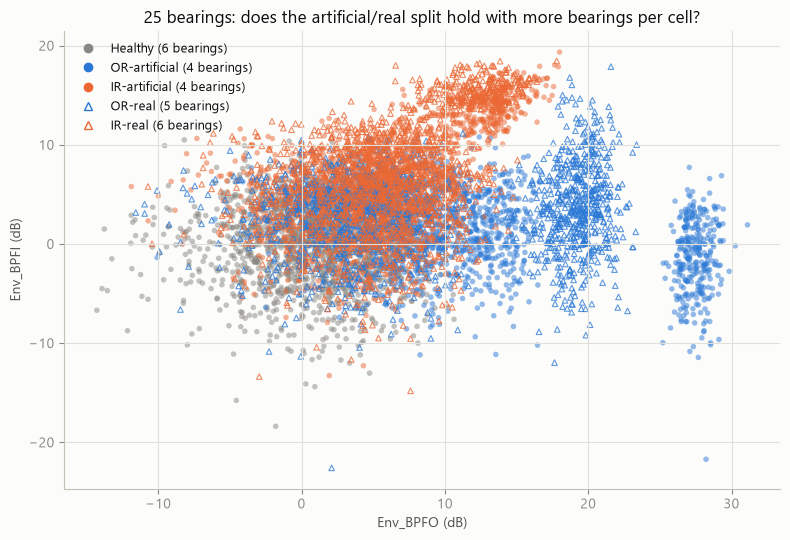

In [3]:
FEATURES_ALL = [c for c in dataset.columns if c not in ("Code", "Condition", "Domain", "Run")]
FEATURE_SETS = {
    "All (12)":              FEATURES_ALL,
    "Envelope (5)":          [c for c in FEATURES_ALL if c.startswith("Env_")],
    "Env fundamentals (3)":  ["Env_BPFO_dB", "Env_BPFI_dB", "Env_fr_dB"],
    "Time-domain (2)":       ["Vib_RMS", "Vib_CrestFactor"],
    "Current/MCSA (5)":      [c for c in FEATURES_ALL if c.startswith("Cur_")],
}
TRAIN = dataset[dataset["Domain"] != "real"]   # healthy + artificial, 14 bearings
TEST = dataset[dataset["Domain"] == "real"]    # 11 real bearings, held out from ALL training
REAL_BEARINGS = TEST[["Code", "Condition"]].drop_duplicates().sort_values(["Condition", "Code"])
RF_KW = dict(n_estimators=300, random_state=0, n_jobs=-1)

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
CLASS_COLOR = {"Healthy": MUTED, "OR": C_BLUE, "IR": C_ORANGE}

fig, ax = plt.subplots(figsize=(8, 5.5))
for code, cond, dom in BEARINGS:
    sub = dataset[dataset["Code"] == code]
    marker = "o" if dom != "real" else "^"
    fc = "none" if dom == "real" else CLASS_COLOR[cond]
    ec = CLASS_COLOR[cond]
    ax.scatter(sub["Env_BPFO_dB"], sub["Env_BPFI_dB"], s=16, alpha=0.5 if dom != "real" else 0.75,
               marker=marker, facecolors=fc, edgecolors=ec if dom == "real" else "none",
               linewidths=0.8)
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], marker="o", color=CLASS_COLOR["Healthy"], linestyle="", label="Healthy (6 bearings)"),
           Line2D([0], [0], marker="o", color=C_BLUE, linestyle="", label="OR-artificial (4 bearings)"),
           Line2D([0], [0], marker="o", color=C_ORANGE, linestyle="", label="IR-artificial (4 bearings)"),
           Line2D([0], [0], marker="^", markerfacecolor="none", markeredgecolor=C_BLUE, linestyle="", label="OR-real (5 bearings)"),
           Line2D([0], [0], marker="^", markerfacecolor="none", markeredgecolor=C_ORANGE, linestyle="", label="IR-real (6 bearings)")]
ax.legend(handles=handles, fontsize=9, loc="upper left")
ax.set_xlabel("Env_BPFO (dB)")
ax.set_ylabel("Env_BPFI (dB)")
ax.set_title("25 bearings: does the artificial/real split hold with more bearings per cell?")
plt.tight_layout()
plt.show()

## Reading the sanity scatter

Notebook 04's tidy geometry is gone. With 6 healthy, 8 artificial and 11 real
bearings on one canvas:

- No class is a single cluster anymore — every class is a **family of
  bearing-shaped islands**. OR-artificial alone spans three: the EDM bearing
  near 27 dB and the engraver/drill bearings far lower. The clean
  "healthy | corridor | artificial" picture of notebook 04 was an artifact of
  having one bearing per cell.
- IR-real and IR-artificial overlap heavily (good news for transfer), but a
  visible part of the OR-real population sits **inside the healthy cloud** —
  those windows are undetectable at these coordinates, whoever the classifier.
- So before any model runs, the scaled data already says: bearing-to-bearing
  variability is comparable to the class signal itself. The question is no
  longer just "does artificial transfer to real?" but "does *anything*
  transfer to an unseen bearing?"

## Experiment A (scaled) — one model, eleven honest test bearings

Train **once** on all 14 healthy+artificial bearings, score each of the 11
real bearings **separately** (each is fully held out from training by
construction — no leakage question here, unlike the in-domain ceiling below).
Compare the full 12-feature model against the physics-anchored fundamentals
that won notebook 04's ablation.

In [4]:
def per_bearing_transfer(features):
    rf = RandomForestClassifier(**RF_KW).fit(TRAIN[features], TRAIN["Condition"])
    rows = []
    for _, (code, cond) in REAL_BEARINGS.iterrows():
        sub = TEST[TEST["Code"] == code]
        pred = rf.predict(sub[features])
        rows.append({"Code": code, "Condition": cond,
                     "Accuracy": (pred == cond).mean(),
                     "Missed (-> Healthy)": (pred == "Healthy").mean()})
    return rf, pd.DataFrame(rows).set_index("Code")


rf_all, per_bearing_all = per_bearing_transfer(FEATURE_SETS["All (12)"])
_, per_bearing_fund = per_bearing_transfer(FEATURE_SETS["Env fundamentals (3)"])

summary = per_bearing_all[["Condition", "Accuracy", "Missed (-> Healthy)"]].copy()
summary["Accuracy (fundamentals)"] = per_bearing_fund["Accuracy"]
summary["Missed (fundamentals)"] = per_bearing_fund["Missed (-> Healthy)"]
print(f"All 12 features : {per_bearing_all['Accuracy'].mean():.1%} +/- "
      f"{per_bearing_all['Accuracy'].std():.1%}  across {len(per_bearing_all)} real bearings "
      f"(range {per_bearing_all['Accuracy'].min():.1%}-{per_bearing_all['Accuracy'].max():.1%})")
print(f"Fundamentals    : {per_bearing_fund['Accuracy'].mean():.1%} +/- "
      f"{per_bearing_fund['Accuracy'].std():.1%}  across {len(per_bearing_fund)} real bearings "
      f"(range {per_bearing_fund['Accuracy'].min():.1%}-{per_bearing_fund['Accuracy'].max():.1%})")
print(f"\n(notebook 04's single-bearing number was 20.8% on KA04+KI04)")
summary.style.format({c: "{:.1%}" for c in summary.columns if c != "Condition"})

All 12 features : 54.4% +/- 40.2%  across 11 real bearings (range 0.0%-100.0%)
Fundamentals    : 60.6% +/- 36.4%  across 11 real bearings (range 4.3%-100.0%)

(notebook 04's single-bearing number was 20.8% on KA04+KI04)


,Condition,Accuracy,Missed (-> Healthy),Accuracy (fundamentals),Missed (fundamentals)
Code,,,,,
KI04,IR,88.0%,1.7%,99.3%,0.7%
KI14,IR,95.0%,1.0%,67.7%,24.0%
KI16,IR,74.3%,9.7%,78.7%,10.7%
KI17,IR,38.7%,1.7%,34.7%,51.0%
KI18,IR,100.0%,0.0%,100.0%,0.0%
KI21,IR,0.0%,0.0%,80.0%,10.0%
KA04,OR,99.7%,0.0%,99.3%,0.0%
KA15,OR,3.0%,96.7%,4.3%,68.7%
KA16,OR,54.3%,0.0%,69.0%,0.0%


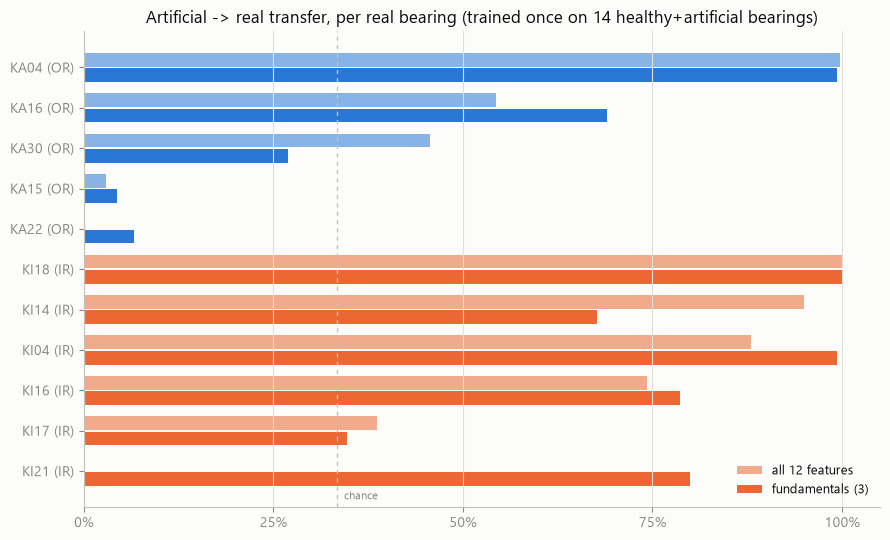

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(summary))
order = summary.sort_values(["Condition", "Accuracy"]).index
s = summary.loc[order]
h = 0.34
colors = [CLASS_COLOR[c] for c in s["Condition"]]
ax.barh(y + h / 2 + 0.02, s["Accuracy"], height=h, color=colors, alpha=0.55, label="all 12 features")
ax.barh(y - h / 2 - 0.02, s["Accuracy (fundamentals)"], height=h, color=colors, label="fundamentals (3)")
ax.axvline(1 / 3, color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(1 / 3 + 0.01, -0.7, "chance", color=MUTED, fontsize=8)
ax.set_yticks(y, [f"{c} ({cond})" for c, cond in zip(s.index, s['Condition'])])
ax.set_xlim(0, 1.05)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="y", visible=False)
ax.set_title("Artificial -> real transfer, per real bearing (trained once on 14 healthy+artificial bearings)")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

## Reading experiment A at scale

- **The mean hides everything: the distribution is bimodal.** 54.4 % ± 40.2
  (all 12) / 60.6 % ± 36.4 (fundamentals) per bearing, with a 0–100 % range:
  KA04, KI04, KI14, KI16, KI18, KI21 are recognized at 68–100 % with the
  fundamentals, while **KA15 (4 %), KA22 (7 %), KI17 (35 %), KA30 (27 %)
  stay near-invisible — and they fail toward "Healthy"** (52–69 % of their
  windows waved through). The dangerous error direction from notebook 04
  persists exactly where it matters.
- **Notebook 04's collapse was half bearing-identity.** The same two test
  bearings (KA04 + KI04) that scored 20.8 % there score **≈ 94 %** here with
  the identical feature table — the only change is training on four
  artificial damage variants per class (EDM, engraver ×2, drill) instead of
  one. **Diversity of artificial damage is an enormous, cheap transfer
  lever** — directly actionable for the digital twin: simulate many damage
  variants, not one canonical fault.
- Fundamentals rescue KI21 (0 % → 80 %) but cannot rescue KA15/KA22: their
  BPFO envelope signature is genuinely weak, not merely mis-thresholded.
  Whatever the feature set, roughly two of five real outer-race bearings are
  invisible to this pipeline.

## The honest in-domain ceiling: leave-one-*bearing*-out

Notebook 04's "100% in-domain" grouped by *recording* — different runs of the
*same* bearing, which mostly differ by noise. That is a much easier holdout
than a genuinely new bearing. Redo it properly: `LeaveOneGroupOut` with
`groups = Code`, so every fold tests on a bearing the model has never seen at
all — the same standard now applied to the real-domain evaluation above.

In [6]:
logo = LeaveOneGroupOut()
rows = []
for name, feats in FEATURE_SETS.items():
    cv = cross_val_score(RandomForestClassifier(**RF_KW), TRAIN[feats], TRAIN["Condition"],
                         groups=TRAIN["Code"], cv=logo)
    a = TEST.groupby("Code").apply(
        lambda g, f=feats: (RandomForestClassifier(**RF_KW).fit(TRAIN[f], TRAIN['Condition'])
                            .predict(g[f]) == g['Condition'].iloc[0]).mean(),
        include_groups=False)
    rows.append({"Features": name,
                 "In-domain (leave-1-bearing-out)": cv.mean(),
                 "In-domain std": cv.std(),
                 "Art->Real (per-bearing mean)": a.mean(),
                 "Art->Real std": a.std()})
ablation = pd.DataFrame(rows).set_index("Features")
ablation.style.format({c: "{:.1%}" for c in ablation.columns})

,In-domain (leave-1-bearing-out),In-domain std,Art->Real (per-bearing mean),Art->Real std
Features,,,,
All (12),43.2%,42.3%,54.4%,40.2%
Envelope (5),65.2%,30.8%,61.8%,35.4%
Env fundamentals (3),69.3%,26.8%,60.6%,36.4%
Time-domain (2),30.4%,43.8%,32.8%,42.3%
Current/MCSA (5),28.7%,31.6%,24.6%,28.7%


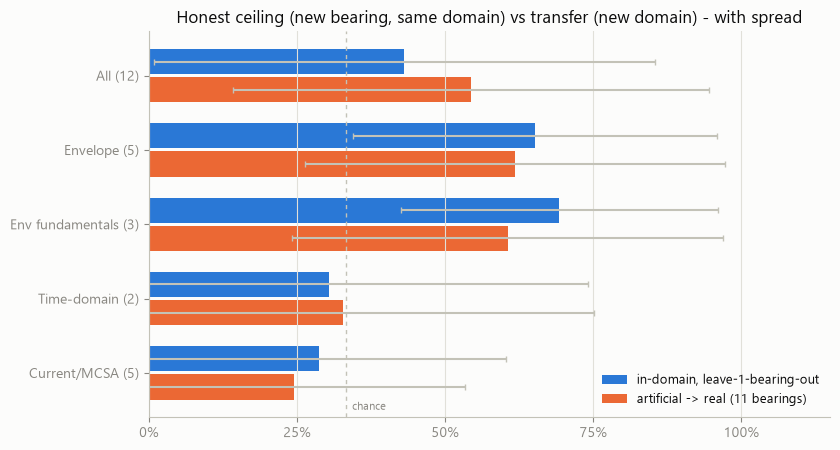

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
y = np.arange(len(ablation))[::-1]
h = 0.34
ax.barh(y + h / 2 + 0.02, ablation["In-domain (leave-1-bearing-out)"], height=h, color=C_BLUE,
        xerr=ablation["In-domain std"], error_kw=dict(ecolor=BASE, capsize=2),
        label="in-domain, leave-1-bearing-out")
ax.barh(y - h / 2 - 0.02, ablation["Art->Real (per-bearing mean)"], height=h, color=C_ORANGE,
        xerr=ablation["Art->Real std"], error_kw=dict(ecolor=BASE, capsize=2),
        label="artificial -> real (11 bearings)")
ax.axvline(1 / 3, color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(1 / 3 + 0.01, ax.get_ylim()[0] + 0.1, "chance", color=MUTED, fontsize=8)
ax.set_yticks(y, ablation.index)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1.15)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title("Honest ceiling (new bearing, same domain) vs transfer (new domain) - with spread")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

## Reading the honest ceiling

- **Notebook 04's "100.0 % in-domain" was bearing memorization.** Held out at
  the *bearing* level, the in-domain ceiling drops to **69.3 % ± 26.8**
  (fundamentals) — and only **43.2 % ± 42.3** with all 12 features, *worse
  than that same model's transfer score*, because level-fingerprint features
  hurt on any unseen bearing, artificial or real.
- Transfer (60.6 %) now sits **within one standard deviation of the honest
  ceiling** (69.3 %): most of what notebook 04 measured as an
  "artificial→real domain gap" is really a **new-bearing gap** that exists
  inside the artificial domain too; the domain shift itself costs roughly
  nine points on top.
- The feature ranking survives scaling: fundamentals best on both axes;
  time-domain collapses to 30–33 % (its 47.2 % in notebook 04 was a KA04
  fluke); current/MCSA stays at chance — the null result is now confirmed
  across 25 bearings.
- For RQ4 this reframes the enemy: not only "sim vs real" but **unit-to-unit
  variability**, which the twin will face even with a perfect simulator.

## Do the notebook-04 "poisons" still poison at scale?

With 6 healthy and 4+4 artificial bearings instead of 1 each, the
rig-harmonic and bearing-level-RMS explanations from notebook 04 get a real
test: if they were genuine effects (not one bearing's idiosyncrasy), the same
pattern should appear averaged across many bearings.

           Env_BPFOh2_dB       Vib_RMS      
                    mean   std    mean   std
Domain                                      
artificial          9.49  7.47    0.35  0.16
healthy            10.13  5.59    0.29  0.09
real                5.82  4.79    0.34  0.12


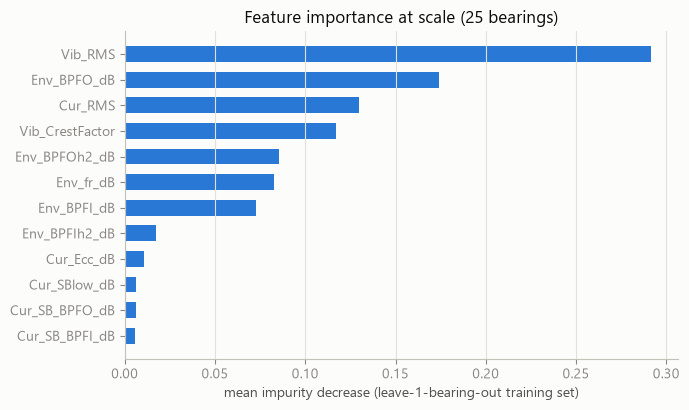

top 4: Vib_RMS, Env_BPFO_dB, Cur_RMS, Vib_CrestFactor


In [8]:
poison_means = dataset.groupby("Domain")[["Env_BPFOh2_dB", "Vib_RMS"]].agg(["mean", "std"])
print(poison_means.round(2))

rf_fund, _ = per_bearing_transfer(FEATURE_SETS["Env fundamentals (3)"])
imp = pd.Series(rf_all.feature_importances_, index=FEATURES_ALL).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(imp.index, imp.values, color=C_BLUE, height=0.62)
ax.grid(axis="y", visible=False)
ax.set_xlabel("mean impurity decrease (leave-1-bearing-out training set)")
ax.set_title("Feature importance at scale (25 bearings)")
plt.tight_layout()
plt.show()
print("top 4:", ", ".join(imp.sort_values(ascending=False).index[:4]))

## The poisons at scale

- **The contamination generalizes:** across six healthy bearings,
  `Env_BPFOh2_dB` still reads *higher in healthy* (10.1 ± 5.6 dB — the rig
  harmonic family) than in real damage (5.8 ± 4.8). Any split on it pushes
  real damage toward Healthy on every bearing, not just K001.
- **`Vib_RMS` is confirmed as a bearing fingerprint, not a fault feature:**
  the domain means nearly coincide (healthy 0.29, artificial 0.35, real
  0.34) with wide spreads. Yet the forest ranks it **#1** (0.29 importance),
  with `Cur_RMS` (#3) and `Vib_CrestFactor` (#4) right behind: **impurity
  importance actively anti-selects transferable features**, because level
  fingerprints are the fastest way to separate the *training bearings*.
  Feature choice must come from physics, not from the importance chart.

## Few-shot mixing, bearing-level: how many real bearings does it take?

Notebook 04 tested mixing in *recordings* of the same one or two real
bearings. With 11 real bearings available, this is now a fairer test: for
each held-out real bearing, mix `k` *other* real bearings (drawn at random,
of either fault type — a realistic "some real data available, not
necessarily this exact fault") into training, and average over all 11 held-out
bearings and several random draws.

In [9]:
rng = np.random.default_rng(0)
FEATS = FEATURE_SETS["All (12)"]
real_codes = REAL_BEARINGS["Code"].tolist()

mix_rows = []
for k in (0, 1, 2, 3, 5):
    accs = []
    for held_out in real_codes:
        pool = [c for c in real_codes if c != held_out]
        n_draws = 1 if k == 0 else min(5, max(1, len(pool) - k + 1))
        for draw in range(n_draws):
            chosen = rng.choice(pool, size=k, replace=False) if k else []
            tr = pd.concat([TRAIN, dataset[dataset["Code"].isin(chosen)]])
            te = dataset[dataset["Code"] == held_out]
            pred = RandomForestClassifier(**RF_KW).fit(tr[FEATS], tr["Condition"]).predict(te[FEATS])
            accs.append((pred == te["Condition"].iloc[0]).mean())
    mix_rows.append({"k": k, "mean": np.mean(accs), "std": np.std(accs), "n": len(accs)})
mix_df = pd.DataFrame(mix_rows)
mix_df.style.format({"mean": "{:.1%}", "std": "{:.1%}"})

,k,mean,std,n
0,0,54.4%,38.4%,11
1,1,50.3%,40.3%,55
2,2,52.1%,39.5%,55
3,3,53.6%,42.2%,55
4,5,55.8%,41.2%,55


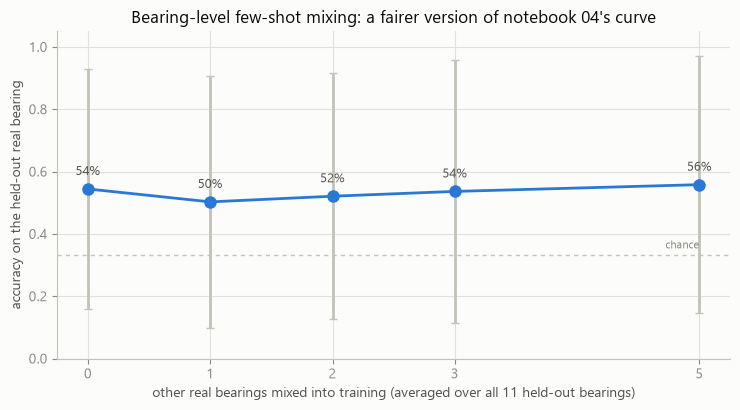

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.errorbar(mix_df["k"], mix_df["mean"], yerr=mix_df["std"], color=C_BLUE, lw=2,
            marker="o", markersize=8, capsize=3, ecolor=BASE)
for _, r in mix_df.iterrows():
    ax.annotate(f"{r['mean']:.0%}", (r["k"], r["mean"]), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=9, color=INK2)
ax.axhline(1 / 3, color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(mix_df["k"].max(), 1 / 3 + 0.02, "chance", color=MUTED, fontsize=8, ha="right")
ax.set_xticks(mix_df["k"])
ax.set_xlabel("other real bearings mixed into training (averaged over all 11 held-out bearings)")
ax.set_ylabel("accuracy on the held-out real bearing")
ax.set_ylim(0, 1.05)
ax.set_title("Bearing-level few-shot mixing: a fairer version of notebook 04's curve")
plt.tight_layout()
plt.show()

### Follow-up (2026-08-13): is the flat curve an artifact of the poisoned features?

Fair challenge: the mixing experiment above used **all 12 features** — the set
the importance chart says is dominated by bearing fingerprints (`Vib_RMS`,
`Cur_RMS`). If those fingerprints drown out whatever the mixed-in real
bearings could teach, the flat curve might be a feature problem, not a
mixing problem. Same protocol, three physics-anchored fundamentals only —
and a per-bearing k = 0 → 5 breakdown to see *where* any gain lands.

In [11]:
FUND = FEATURE_SETS["Env fundamentals (3)"]
rng = np.random.default_rng(0)

per_bearing = {}   # k -> {code: mean acc over draws}
for k in (0, 1, 2, 3, 5):
    bearing_means, pooled = {}, []
    for held_out in real_codes:
        pool = [c for c in real_codes if c != held_out]
        n_draws = 1 if k == 0 else min(5, max(1, len(pool) - k + 1))
        accs = []
        for _ in range(n_draws):
            chosen = rng.choice(pool, size=k, replace=False) if k else []
            tr = pd.concat([TRAIN, dataset[dataset["Code"].isin(chosen)]])
            te = dataset[dataset["Code"] == held_out]
            pred = (RandomForestClassifier(**RF_KW)
                    .fit(tr[FUND], tr["Condition"]).predict(te[FUND]))
            accs.append((pred == te["Condition"].iloc[0]).mean())
        bearing_means[held_out] = np.mean(accs)
        pooled += accs
    per_bearing[k] = bearing_means
    print(f"k={k}: {np.mean(pooled):6.1%} +/- {np.std(pooled):5.1%}  (n={len(pooled)})")

delta = (pd.DataFrame({"k=0": per_bearing[0], "k=5": per_bearing[5]})
         .join(REAL_BEARINGS.set_index("Code"))
         .assign(delta=lambda d: d["k=5"] - d["k=0"])
         .sort_values("delta"))
print()
print(delta.to_string(formatters={"k=0": "{:.1%}".format, "k=5": "{:.1%}".format,
                                  "delta": "{:+.1%}".format}))

k=0:  60.6% +/- 34.7%  (n=11)


k=1:  59.9% +/- 34.4%  (n=55)


k=2:  61.5% +/- 33.8%  (n=55)


k=3:  62.1% +/- 33.9%  (n=55)


k=5:  65.2% +/- 34.2%  (n=55)

        k=0    k=5 Condition  delta
KI21  80.0%  79.5%        IR  -0.5%
KI04  99.3%  99.1%        IR  -0.2%
KI18 100.0% 100.0%        IR  +0.0%
KA04  99.3%  99.8%        OR  +0.5%
KI14  67.7%  69.0%        IR  +1.3%
KA30  27.0%  28.8%        OR  +1.8%
KA15   4.3%   7.5%        OR  +3.2%
KI16  78.7%  84.3%        IR  +5.6%
KA22   6.7%  12.8%        OR  +6.1%
KI17  34.7%  45.4%        IR +10.7%
KA16  69.0%  91.0%        OR +22.0%


## Reading the follow-up

- **The curve is no longer perfectly flat — but it is not a fix either.**
  With the fundamentals, k = 0 already starts higher (60.6 % vs 54.4 %) and
  mixing five real bearings adds ≈ 4.6 points (→ 65.2 %); the same protocol
  with all 12 features added ~1 point. So yes — the bearing-fingerprint
  features were partly drowning out what the mixed-in real bearings could
  teach: **feature quality and data strategy interact.**
- **Half of that gain is one bearing.** KA16 jumps +22 points (69 → 91 %),
  KI17 +11; every other bearing moves ≤ 6. A mean lifted by a single large
  responder is not a mechanism to build on.
- **The invisible bearings stay invisible:** KA15 4 → 8 %, KA22 7 → 13 %,
  KA30 27 → 29 %. Neither cleaner features nor five real bearings in
  training can recover a signature that is absent at these frequencies —
  root-causing those bearings (next steps) remains the priority.
- **Net for RQ4:** finding 4 stands, refined — bearing-level mixing is a
  *small* lever once features are physics-anchored (nothing like notebook
  04's leakage-inflated 99 %), and it does not touch the failure cases that
  matter most.

## Findings (executed 2026-08-12)

1. **The scaled RQ4 numbers replace notebook 04's.** One Random Forest
   trained on 14 healthy + artificial bearings recognizes real damage at
   **60.6 % ± 36.4 per bearing** (envelope fundamentals; 54.4 % ± 40.2 with
   all 12 features), **bimodally**: seven of eleven real bearings at
   68–100 %, while KA15 (4 %), KA22 (7 %), KA30 (27 %) and KI17 (35 %) are
   near-invisible and fail toward "Healthy" — the dangerous direction.
2. **Notebook 04's collapse was half bearing-identity, and damage-variant
   diversity is the biggest lever found so far:** the same KA04 + KI04 test
   pair jumps 20.8 % → ≈ 94 % purely by training on four artificial variants
   per class (EDM, engraver, drill) instead of one. Twin implication:
   simulate *many* damage variants per fault class, not a canonical one.
3. **The honest in-domain ceiling is ≈ 69 %, not 100 %.** Leave-one-
   *bearing*-out CV inside the artificial domain: 69.3 % ± 26.8
   (fundamentals), 43.2 % ± 42.3 (all 12 — worse than its own transfer
   score). Recording-level CV (notebook 04's 100 %) measured bearing
   memorization. Transfer sits within one σ of the ceiling: **the dominant
   difficulty is any unseen bearing; the artificial→real shift adds ~9
   points on top.**
4. **Notebook 04's few-shot miracle was leakage.** Recording-level mixing
   (1 recording/class → 99.2 %) put the *test bearing itself* into training.
   Mixed at bearing level and tested on a held-out bearing, the curve is
   **flat: 54 → 50 → 52 → 54 → 56 % for k = 0, 1, 2, 3, 5** real bearings.
   RQ4's "mix a modest fraction of real data" hypothesis is **refuted at
   unit level** — real data helps the *unit it comes from* (per-unit
   calibration), not unseen units. *(Refined by the follow-up below:
   with the three fundamentals the curve gains ≈ 4.6 pts by k = 5
   [60.6 → 65.2 %], but half of that is one bearing, KA16, and the
   invisible bearings stay invisible.)*
5. **Impurity importance anti-selects transferable features.** At scale the
   forest's top features are Vib_RMS (0.29), Env_BPFO, Cur_RMS,
   Vib_CrestFactor — level fingerprints that separate training bearings —
   while the contaminated 2×BPFO harmonic still reads higher in healthy
   (10.1 dB) than in real damage (5.8 dB). Physics picks features;
   importance charts pick memorization.
6. **Caveats:** one operating condition (N15_M07_F10); severity levels vary
   across bearings (KI16 is level 3, most are level 1) with no per-severity
   analysis yet; 5 OR vs 6 IR real bearings; single classifier family (RF).